# Clustering Case Study - TMDB 5000 Movies
**Datasets:** `tmdb_5000_movies.csv` and `tmdb_5000_credits.csv` (keep both files in the same folder as this notebook)

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram

import warnings
warnings.filterwarnings("ignore")

# Section A - Dataset & EDA

## A1 - Dataset loading & audit

### Load the dataset
The movies file has `id` and the credits file has `movie_id`. Both mean the same thing, so we join on them.

In [2]:
movies  = pd.read_csv("tmdb_5000_movies.csv")
credits = pd.read_csv("tmdb_5000_credits.csv")

# credits has the same 'title' column, so drop it before merging
df = movies.merge(credits.drop(columns="title"), left_on="id", right_on="movie_id")
df.head(3)

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,...,runtime,spoken_languages,status,tagline,title,vote_average,vote_count,movie_id,cast,crew
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...",...,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800,19995,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...",...,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500,285,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...",...,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466,206647,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."


### Shape and data types

In [3]:
print("Shape:", df.shape)
print()
print(df.dtypes)

Shape: (4803, 23)

budget                    int64
genres                      str
homepage                    str
id                        int64
keywords                    str
original_language           str
original_title              str
overview                    str
popularity              float64
production_companies        str
production_countries        str
release_date                str
revenue                   int64
runtime                 float64
spoken_languages            str
status                      str
tagline                     str
title                       str
vote_average            float64
vote_count                int64
movie_id                  int64
cast                        str
crew                        str
dtype: object


### Missing values

In [4]:
missing = df.isnull().sum()
print(missing[missing > 0])

homepage        3091
overview           3
release_date       1
runtime            2
tagline          844
dtype: int64


## A2 - EDA visualisations

### Distribution of each feature

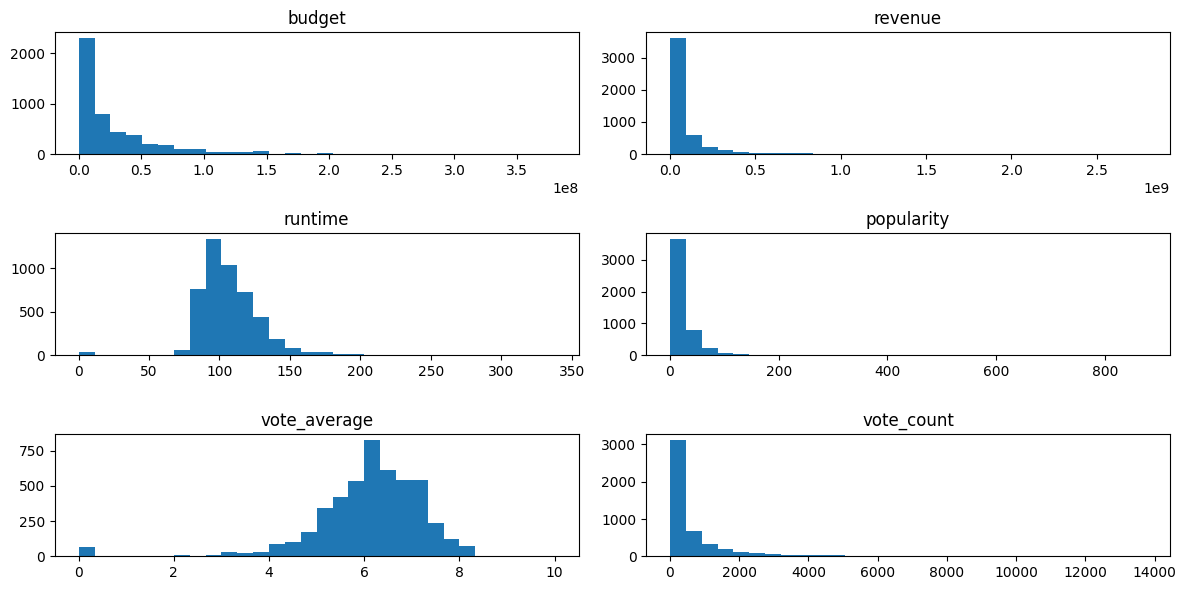

In [5]:
num_features = ["budget", "revenue", "runtime", "popularity", "vote_average", "vote_count"]

df[num_features].hist(bins=30, figsize=(12, 6),grid=False)
plt.tight_layout()
plt.show()

**Observation:** `budget`, `revenue`, `popularity` and `vote_count` are heavily right-skewed: most movies are small and a few are huge.
The first bar of `budget` and `revenue` also holds many zeros, which are missing values, not real zeros.
`vote_average` looks like a bell shape around 6, and `runtime` is centred near 100 minutes.

### Correlation heatmap

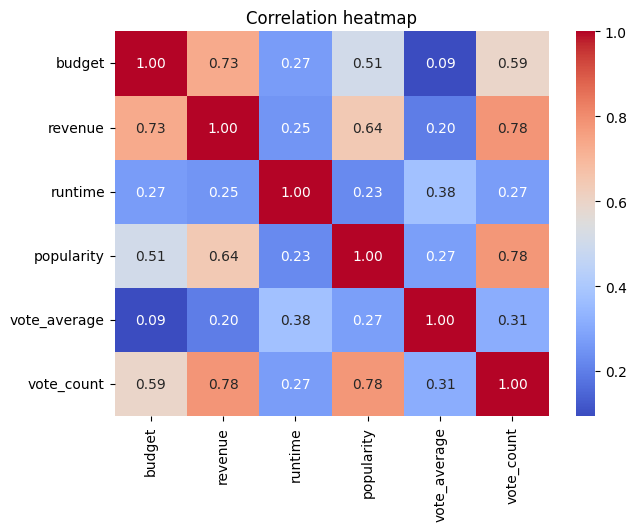

In [6]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_features].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.show()

**Observation:** `revenue`, `vote_count` and `popularity` are strongly related to each other (about 0.64 to 0.78), and `budget` goes with `revenue` (0.73).
`vote_average` has only weak links with the other features (the highest is `runtime`, 0.38).

## A3 - Insight commentary

Summary of what the EDA showed:

- Several features are very skewed, so we will use a `log` transform before scaling.
- `budget` and `revenue` have many zeros that are really missing values, so they need cleaning.
- Some features are strongly correlated (`revenue`, `vote_count`, `popularity`, `budget`), so the movies group mainly by their size and success.
- Movies with no votes have a meaningless rating, so we will remove them.

**Note:** the guidelines for Section A and B also mention a target variable, a train/test split and feature-target plots.
Clustering has no target, so those parts are not applicable and are left out.

# Section B - Preprocessing & Feature Engineering

## B1 - Data cleaning

### Missing values
- `budget`, `revenue` and `runtime` use 0 for "missing", so we change 0 to missing and fill with the **median** (the median is not pulled up by blockbusters like the mean would be).
- Movies with `vote_average` 0 have no votes, so there is no real rating. We **remove** them.
- One movie has no `release_date`, so we remove it.
- `homepage` and `tagline` are mostly empty and are not used for clustering, so we **drop these two columns** (no movies are lost). `overview` has only 2 missing values, so we fill them with "Unknown".

In [7]:
# 1) 0 means missing in these columns -> change 0 to missing, then fill with the median
for col in ["budget", "revenue", "runtime"]:
    df[col] = df[col].replace(0, np.nan)
    print(col, "missing:", df[col].isnull().sum())
    df[col] = df[col].fillna(df[col].median())

# 2) remove movies with no rating and no release date
df = df[df["vote_average"] > 0]
df = df.dropna(subset=["release_date"])

# 3) text columns: homepage and tagline are mostly empty and not used, so drop them
df = df.drop(columns=["homepage", "tagline"])

# overview has only 2 missing values, so fill them with "Unknown"
df["overview"] = df["overview"].fillna("Unknown")

print("Rows left:", len(df))
print("Missing values left:", df.isnull().sum().sum())

budget missing: 1037
revenue missing: 1427
runtime missing: 37
Rows left: 4740
Missing values left: 0


### Duplicates

In [8]:
print("Duplicate ids:", df.duplicated(subset="id").sum())
print("Duplicate title + date:", df.duplicated(subset=["title", "release_date"]).sum())

Duplicate ids: 0
Duplicate title + date: 0


There are no duplicates, so nothing needs to be removed.

### Outliers
We count outliers with the IQR rule, then **cap** them at the 1st and 99th percentile.
We cap instead of removing, so we do not lose any movies.

In [9]:
cap_cols = ["budget", "revenue", "runtime", "popularity", "vote_count"]

for col in cap_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    outliers = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(col, "outliers:", outliers)

    low = df[col].quantile(0.01)
    high = df[col].quantile(0.99)
    df[col] = df[col].clip(low, high)

budget outliers: 419
revenue outliers: 576
runtime outliers: 146
popularity outliers: 271
vote_count outliers: 498


## B2 - Encoding, scaling 

A train/test split is not needed here, because clustering has no target to predict. So we only do encoding and scaling.

### Encode the categorical columns
- `original_language` becomes `is_english` (1 or 0), because almost all movies are English.
- `genres` is a list, so we use the **first genre** as `main_genre`, keep the 5 most common ones, call the rest "Other", and one-hot encode it.

In [10]:
df["is_english"] = (df["original_language"] == "en").astype(int)

df["main_genre"] = df["genres"].apply(lambda x: json.loads(x)[0]["name"] if len(json.loads(x)) > 0 else "Other")
top5 = df["main_genre"].value_counts().head(5).index
df["main_genre"] = df["main_genre"].where(df["main_genre"].isin(top5), "Other")

df = pd.get_dummies(df, columns=["main_genre"], drop_first=True, dtype=int)

# the original columns are not needed after encoding
df = df.drop(columns=["original_language", "genres"])

genre_cols = [c for c in df.columns if c.startswith("main_genre_")]
print(genre_cols)

['main_genre_Adventure', 'main_genre_Comedy', 'main_genre_Drama', 'main_genre_Horror', 'main_genre_Other']


In [11]:
df.head()

,budget,id,keywords,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,...,vote_count,movie_id,cast,crew,is_english,main_genre_Adventure,main_genre_Comedy,main_genre_Drama,main_genre_Horror,main_genre_Other
0,195000000.0,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",Avatar,"In the 22nd century, a paraplegic Marine is di...",121.269116,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,8.276478e+08,...,6248.03,19995,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de...",1,0,0,0,0,0
1,195000000.0,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",121.269116,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,8.276478e+08,...,4500.00,285,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de...",1,1,0,0,0,0
2,195000000.0,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,8.276478e+08,...,4466.00,206647,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de...",1,0,0,0,0,0
3,195000000.0,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,8.276478e+08,...,6248.03,49026,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de...",1,0,0,0,0,0
4,195000000.0,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,2.841391e+08,...,2124.00,49529,"[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de...",1,0,0,0,0,0


### Scale the numeric features
- First `log1p` on the skewed columns to shrink the big gap between small and huge movies.
- Then `StandardScaler`, so every feature has mean 0 and standard deviation 1. Without scaling, big numbers like `revenue` would control the distance calculation.

In [12]:
num_cols = ["budget", "revenue", "runtime", "popularity", "vote_average", "vote_count"]
skewed = ["budget", "revenue", "popularity", "vote_count"]

df_num = df[num_cols].copy()
df_num[skewed] = np.log1p(df_num[skewed])

scaler = StandardScaler()
scaled = pd.DataFrame(scaler.fit_transform(df_num), columns=num_cols, index=df.index)

scaled.describe().round(2)

,budget,revenue,runtime,popularity,vote_average,vote_count
count,4740.00,4740.00,4740.00,4740.00,4740.00,4740.00
mean,0.00,0.00,-0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-4.15,-4.19,-1.60,-2.21,-5.83,-2.54
25%,-0.31,-0.26,-0.71,-0.67,-0.59,-0.67
50%,0.16,0.14,-0.19,0.10,0.03,0.11
75%,0.57,0.51,0.54,0.75,0.64,0.73
max,1.73,1.85,3.68,2.01,3.93,1.90


## B3 - Feature engineering

### Create new features
We create 3 new features from the columns we have not used yet:

- `cast_size`: number of people in the cast (counted from the `cast` column).
- `crew_size`: number of people in the crew (counted from the `crew` column).
- `release_year`: year taken from `release_date`.

**Why they may help:** cast and crew size show how big the production was, which `budget` alone does not show.
`release_year` shows the era of the movie (older and newer movies behave differently). So the clusters can separate movies better.

In [13]:
df["cast_size"] = df["cast"].apply(lambda x: len(json.loads(x)))
df["crew_size"] = df["crew"].apply(lambda x: len(json.loads(x)))
df["release_year"] = pd.to_datetime(df["release_date"]).dt.year

new_cols = ["cast_size", "crew_size", "release_year"]

# scale the new features too
scaled_new = pd.DataFrame(StandardScaler().fit_transform(df[new_cols]), columns=new_cols, index=df.index)

df[new_cols].describe().round(1)

,cast_size,crew_size,release_year
count,4740.0,4740.0,4740.0
mean,22.3,27.3,2002.4
std,19.6,31.7,12.4
min,0.0,0.0,1916.0
25%,12.0,8.0,1999.0
50%,17.0,16.0,2005.0
75%,25.0,33.0,2010.0
max,224.0,435.0,2017.0


### Final data for clustering
- `X` is the table of features with the original values (used later to understand the clusters).
- `X_scaled` is the same table after scaling (used by the algorithms).

In [14]:
encoded_cols = ["is_english"] + genre_cols

X = pd.concat([df[num_cols], df[new_cols], df[encoded_cols]], axis=1)
X_scaled = pd.concat([scaled, scaled_new, df[encoded_cols]], axis=1)

print("X_scaled:", X_scaled.shape)
print("Features:", list(X_scaled.columns))

X_scaled: (4740, 15)
Features: ['budget', 'revenue', 'runtime', 'popularity', 'vote_average', 'vote_count', 'cast_size', 'crew_size', 'release_year', 'is_english', 'main_genre_Adventure', 'main_genre_Comedy', 'main_genre_Drama', 'main_genre_Horror', 'main_genre_Other']


# Section B - Clustering Track

## B1 - Implementation
Both clustering algorithms are fitted here and the cluster labels are obtained.

### K-Means
First we try k = 2 to 10 and store the **inertia** (used for the elbow curve in B2).
We also store the silhouette score for each k to help us decide.

In [15]:
k_values = range(2, 11)
inertias = []
silhouettes = []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_))

pd.DataFrame({"k": list(k_values),
              "Inertia": np.round(inertias, 0),
              "Silhouette": np.round(silhouettes, 3)})

,k,Inertia,Silhouette
0,2,35503.0,0.205
1,3,32194.0,0.146
2,4,29154.0,0.162
3,5,26963.0,0.166
4,6,25532.0,0.161
5,7,24172.0,0.130
6,8,22977.0,0.127
7,9,22090.0,0.125
8,10,21292.0,0.123


**Choosing k:** the elbow curve (plotted in B2) bends gently around k = 5 and the silhouette score has a local peak at k = 5.
k = 2 has a slightly higher silhouette, but only splits the movies into two big groups, which is not very useful, so we choose **k = 5**.
We use the same k for the hierarchical algorithm so both can be compared fairly.

In [16]:
k = 5

kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-Means cluster sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

K-Means cluster sizes:
0     373
1     516
2    1333
3    1889
4     629
Name: count, dtype: int64


### Agglomerative Hierarchical Clustering
We fit the model with the same k = 5. The linkage strategy is chosen in **B2** after comparing four options
(`ward`, `complete`, `average`, `single`). Ward linkage is the best choice (explained there), so we use it here.

In [17]:
agglo = AgglomerativeClustering(n_clusters=k, linkage="ward")
agglo_labels = agglo.fit_predict(X_scaled)

print("Hierarchical (ward) cluster sizes:")
print(pd.Series(agglo_labels).value_counts().sort_index())

Hierarchical (ward) cluster sizes:
0    2318
1    1560
2     307
3     173
4     382
Name: count, dtype: int64


### Look at what each cluster means
Average feature values per cluster (original, un-scaled values) help us understand the groups.

In [18]:
profile = X.copy()
profile["KMeans cluster"] = kmeans_labels
print("K-Means cluster profile (average values):")
display(profile.groupby("KMeans cluster").mean().round(1))

profile = X.copy()
profile["Hierarchical cluster"] = agglo_labels
print("Hierarchical cluster profile (average values):")
display(profile.groupby("Hierarchical cluster").mean().round(1))

K-Means cluster profile (average values):


,budget,revenue,runtime,popularity,vote_average,vote_count,cast_size,crew_size,release_year,is_english,main_genre_Adventure,main_genre_Comedy,main_genre_Drama,main_genre_Horror,main_genre_Other
KMeans cluster,,,,,,,,,,,,,,,
0,9861781.8,44658585.8,118.9,16.3,6.9,366.5,24.1,17.7,1971.0,0.9,0.1,0.1,0.3,0.1,0.2
1,7326005.7,9825718.2,101.8,8.9,6.4,177.3,14.7,14.8,2005.3,0.9,0.0,0.2,0.4,0.1,0.2
2,21280747.4,44166517.0,99.2,4.1,5.5,51.7,13.0,10.7,2004.4,0.9,0.0,0.3,0.3,0.1,0.2
3,39660007.7,101557484.4,106.6,25.3,6.3,735.0,21.9,26.8,2005.4,1.0,0.1,0.2,0.2,0.1,0.2
4,79305039.0,288553251.4,126.5,56.1,6.8,2445.3,49.0,79.9,2005.4,1.0,0.2,0.1,0.2,0.0,0.3


Hierarchical cluster profile (average values):


,budget,revenue,runtime,popularity,vote_average,vote_count,cast_size,crew_size,release_year,is_english,main_genre_Adventure,main_genre_Comedy,main_genre_Drama,main_genre_Horror,main_genre_Other
Hierarchical cluster,,,,,,,,,,,,,,,
0,42194475.6,117155716.4,110.8,27.5,6.4,873.5,23.9,31.9,2003.6,0.9,0.1,0.2,0.3,0.1,0.3
1,20143876.8,43160611.8,96.4,6.1,5.6,102.1,13.7,13.5,2003.8,0.9,0.0,0.4,0.2,0.1,0.2
2,87753187.5,349847318.8,135.7,64.0,7.0,2986.2,62.2,84.1,2004.8,1.0,0.2,0.1,0.3,0.0,0.2
3,7504096.7,30581246.5,125.9,14.8,7.0,310.1,26.5,16.7,1960.7,0.9,0.1,0.1,0.4,0.0,0.2
4,8263991.0,6158602.2,103.2,9.5,6.4,180.8,14.1,15.0,2005.7,0.9,0.0,0.1,0.5,0.1,0.2


## B2 - Evaluation Metrics
Silhouette Score, Davies-Bouldin Index and Calinski-Harabasz Index are reported for **both** algorithms.
The Elbow curve (K-Means) and the Dendrogram (Hierarchical) are also shown here.

How to read the metrics:

| Metric | Better when |
|--------|-------------|
| Silhouette Score (-1 to 1) | **higher** |
| Davies-Bouldin Index (>= 0) | **lower** |
| Calinski-Harabasz Index | **higher** |

### Elbow curve - K-Means

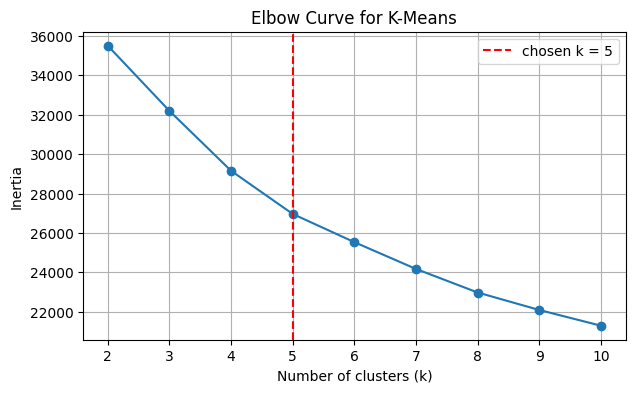

In [19]:
plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertias, marker="o")
plt.axvline(k, color="red", linestyle="--", label=f"chosen k = {k}")
plt.title("Elbow Curve for K-Means")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.legend()
plt.grid(True)
plt.show()

**Reading the curve:** inertia always falls as k grows. The drop is big at first and becomes gradual after about k = 5, so k = 5 is a sensible choice.

### Dendrogram - Hierarchical clustering
We draw one dendrogram for each linkage strategy. The dendrograms are cut to show only the last 30 merges so they stay readable.

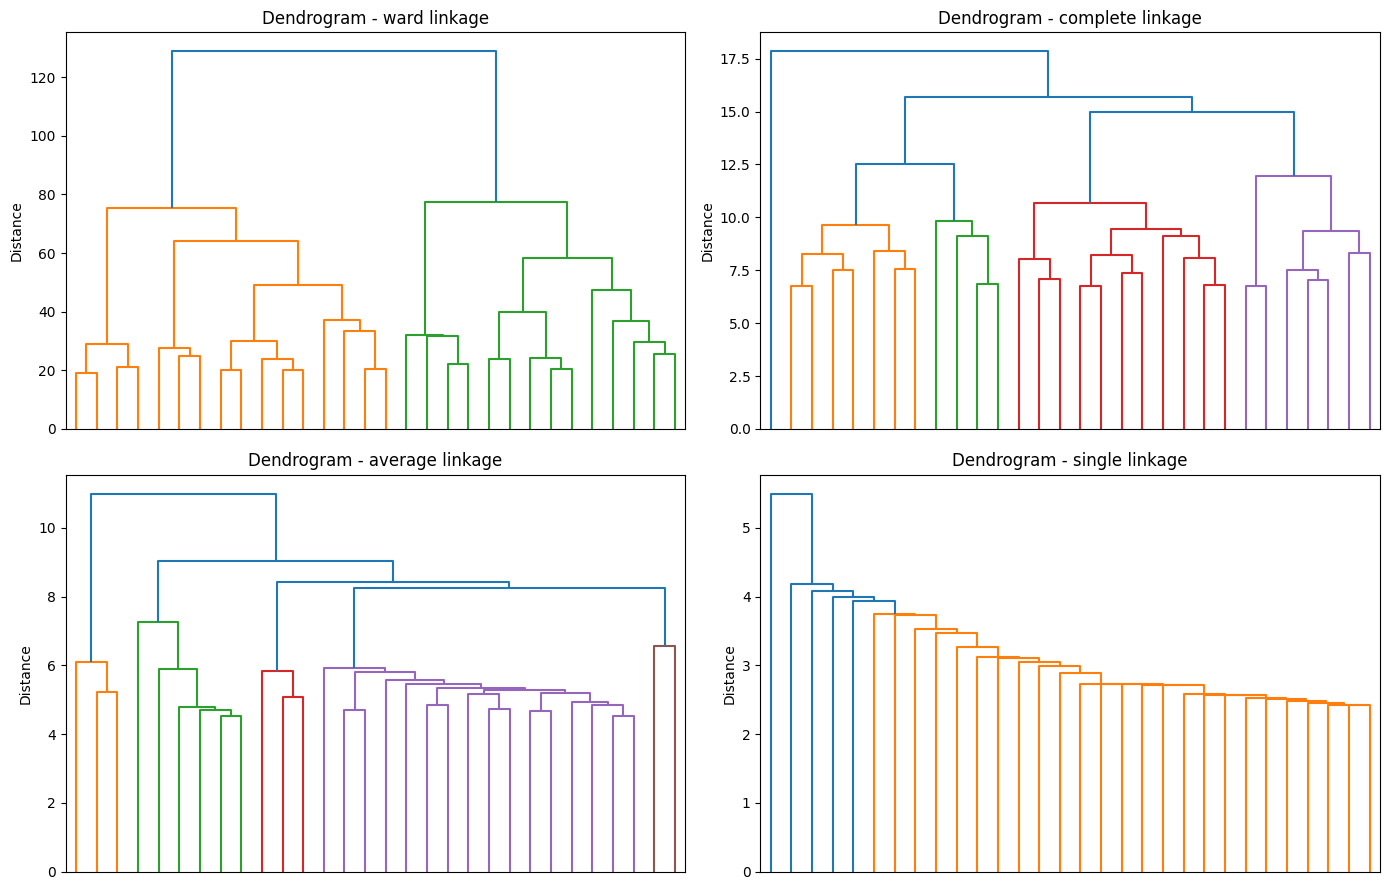

In [20]:
linkage_methods = ["ward", "complete", "average", "single"]

plt.figure(figsize=(14, 9))
for i, method in enumerate(linkage_methods):
    Z = linkage(X_scaled, method=method)
    plt.subplot(2, 2, i + 1)
    dendrogram(Z, truncate_mode="lastp", p=30, no_labels=True)
    plt.title(f"Dendrogram - {method} linkage")
    plt.ylabel("Distance")
plt.tight_layout()
plt.show()

**Reading the dendrograms:** `ward` gives a balanced, clear tree where the big merges at the top are easy to see.
`single` shows the 'chaining' problem (one long chain of merges), and `average` / `complete` are strongly affected by a few extreme movies.

### Compare linkage strategies
We cut each tree into k = 5 clusters and compute the three metrics. We also print the **largest cluster size**,
because a high score with one huge cluster is misleading.

In [21]:
rows = []
for method in linkage_methods:
    labels = AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(X_scaled)
    rows.append({
        "Linkage": method,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Davies-Bouldin": davies_bouldin_score(X_scaled, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled, labels),
        "Largest cluster size": np.bincount(labels).max(),
    })

linkage_table = pd.DataFrame(rows).set_index("Linkage").round(3)
linkage_table

,Silhouette,Davies-Bouldin,Calinski-Harabasz,Largest cluster size
Linkage,,,,
ward,0.136,1.696,641.616,2318
complete,0.155,1.386,454.904,2451
average,0.434,0.829,63.493,4701
single,0.479,0.310,11.344,4736


**Which linkage to use?** `single` and `average` get high silhouette scores, but only because they put almost almost all of the movies
into one giant cluster and leave only tiny clusters of a few outlier movies (see "Largest cluster size"). That is not a useful grouping.
`ward` gives the most balanced clusters of the four, so **ward linkage is used** for the final hierarchical model in B1.

### Final metrics for both algorithms

In [22]:
def get_metrics(data, labels):
    return {
        "Silhouette Score": silhouette_score(data, labels),
        "Davies-Bouldin Index": davies_bouldin_score(data, labels),
        "Calinski-Harabasz Index": calinski_harabasz_score(data, labels),
    }

results = pd.DataFrame({
    "K-Means": get_metrics(X_scaled, kmeans_labels),
    "Agglomerative (ward)": get_metrics(X_scaled, agglo_labels),
}).T.round(3)

results

,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
K-Means,0.166,1.725,839.597
Agglomerative (ward),0.136,1.696,641.616


**Comparison:** see the table above. Higher Silhouette and Calinski-Harabasz and lower Davies-Bouldin means better-defined clusters.
The conclusion at the end of the notebook explains which algorithm performed better on this dataset.

## B3 - Cluster Visualisation
We cannot plot all the features at once, so we reduce the data to 2 dimensions.

### PCA (2 components) - both algorithms

Variance explained by the 2 components: [0.359 0.157]
Total: 0.516


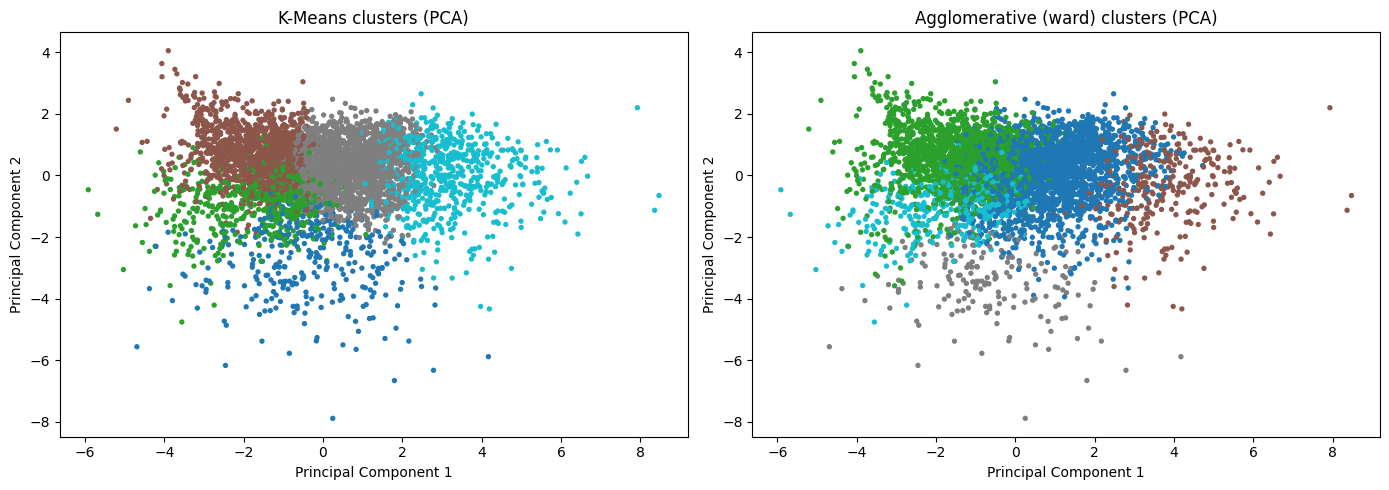

In [23]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("Variance explained by the 2 components:", pca.explained_variance_ratio_.round(3))
print("Total:", pca.explained_variance_ratio_.sum().round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap="tab10", s=8)
axes[0].set_title("K-Means clusters (PCA)")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=agglo_labels, cmap="tab10", s=8)
axes[1].set_title("Agglomerative (ward) clusters (PCA)")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

### t-SNE - both algorithms
t-SNE is slower than PCA but often separates groups more clearly. We compute it once and colour it with each algorithm's labels.

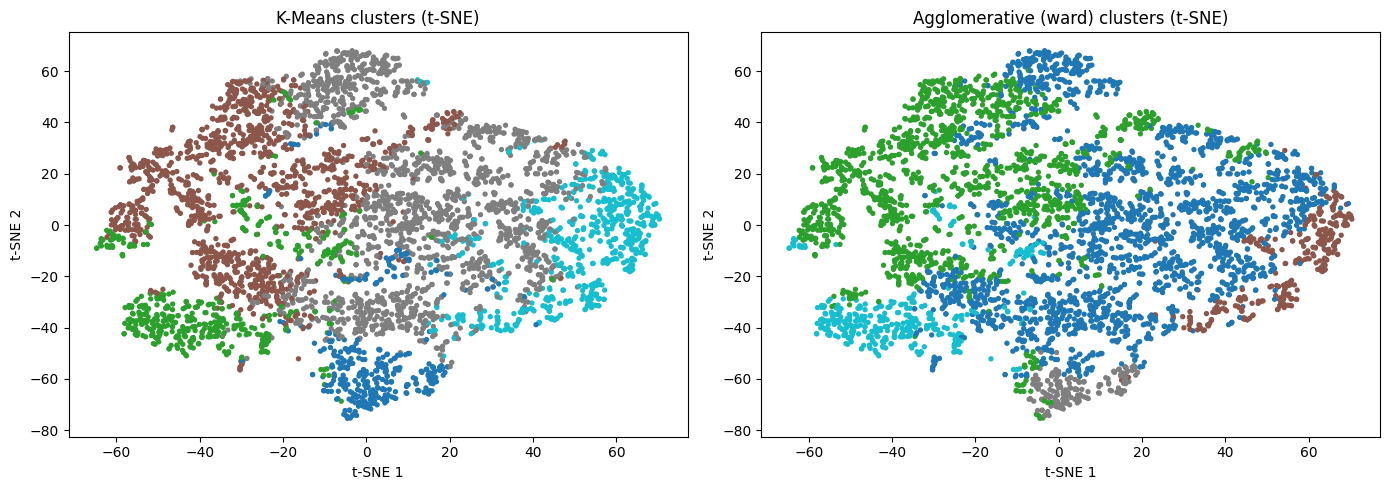

In [24]:
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X_tsne[:, 0], X_tsne[:, 1], c=kmeans_labels, cmap="tab10", s=8)
axes[0].set_title("K-Means clusters (t-SNE)")
axes[0].set_xlabel("t-SNE 1")
axes[0].set_ylabel("t-SNE 2")

axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=agglo_labels, cmap="tab10", s=8)
axes[1].set_title("Agglomerative (ward) clusters (t-SNE)")
axes[1].set_xlabel("t-SNE 1")
axes[1].set_ylabel("t-SNE 2")

plt.tight_layout()
plt.show()

# Conclusion
**Results on the TMDB 5000 movies data (k = 5, 4,740 movies, 15 features):**

| Algorithm | Silhouette (higher is better) | Davies-Bouldin (lower is better) | Calinski-Harabasz (higher is better) |
|-----------|------|------|------|
| K-Means | 0.166 | 1.725 | 839.6 |
| Agglomerative (ward) | 0.136 | 1.696 | 641.6 |

- **K-Means performed better overall:** it is better on Silhouette and Calinski-Harabasz. Ward is only slightly better on Davies-Bouldin (1.696 vs 1.725).
- Both scores are modest, which is normal for real movie data: the groups overlap and there are no sharp boundaries.
- The PCA plot shows the first 2 components explain about 52% of the variance, so the 2D pictures are a simplified view of the 15 features.
- **What the K-Means clusters look like** (from the cluster profile table):
  - one cluster of big-budget blockbusters (high budget, revenue, popularity and vote count, large cast and crew)
  - one cluster of mainstream films with medium-to-high budget and revenue
  - one cluster of older films (average release year about 1971) with high ratings
  - one cluster of low-budget, low-revenue films
  - one cluster of films with very few votes, low popularity and low ratings
- **Linkage comparison:** `single` and `average` linkage gave one giant cluster plus tiny outlier clusters, so `ward` was the sensible hierarchical choice.
- **Possible improvements:** use all the genres of each movie (not only the first one), or try other algorithms such as DBSCAN.